# Notebook 04 — Traditional ML Comparison

**Objective:** Compare Logistic Regression, Random Forest and our validation-selected DNN for final student performance classification **after G2**.

**Evaluation protocol:** Recreate the same 415/104/130 stratified train/validation/test split, use the same 12 selected features, and **evaluate only on validation data**. Notebook 05 will handle final test evaluation.

**Viva:** Logistic Regression is a simple linear baseline; Random Forest learns nonlinear patterns; the DNN learns nonlinear representations through dense layers. We report the results, even if a traditional model outperforms the DNN.


## 1. Imports and project paths

Run this notebook from the `notebooks/` folder. If needed, install packages with:

`python -m pip install pandas numpy matplotlib scikit-learn tensorflow joblib`

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

SEED = 42
DATA_PATH = Path("../data/student-por.csv")
FEATURE_PATH = Path("../models/selected_features.json")
DNN_PATH = Path("../models/tuned_dnn.keras")
DNN_PREPROCESSOR_PATH = Path("../models/tuned_dnn_preprocessor.joblib")
DNN_ENCODER_PATH = Path("../models/tuned_dnn_label_encoder.joblib")
OUTPUT_DIR = Path("../models")

for path in [DATA_PATH, FEATURE_PATH, DNN_PATH, DNN_PREPROCESSOR_PATH, DNN_ENCODER_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Complete Notebooks 01–03 first.")

print("All required project files found.")

All required project files found.


## 2. Load selected features and recreate the same split

`G3` creates the target labels but is **not** an input. Splits use exactly the same seed and stratification as Notebooks 01–03.

**Important:** We create the reserved test partition but never fit, transform, evaluate or inspect it in this notebook.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
feature_config = json.loads(FEATURE_PATH.read_text(encoding="utf-8"))
features = feature_config["selected_features"]

def category(g3):
    if g3 < 10:
        return "Low"
    if g3 < 14:
        return "Average"
    return "Good"

X = df[features].copy()
y = df["G3"].apply(category)
assert len(features) == 12
assert {"G1", "G2"}.issubset(features) and "G3" not in features
assert not X.isna().any().any(), "Dataset has missing values; add training-only imputation."

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)
assert (len(X_train), len(X_val), len(X_test)) == (415, 104, 130)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Reserved test:", len(X_test))
print("Selected features:", features)

Train: 415 | Validation: 104 | Reserved test: 130
Selected features: ['G1', 'G2', 'failures', 'higher', 'absences', 'studytime', 'school', 'Fedu', 'Medu', 'Mjob', 'Dalc', 'famrel']


## 3. Preprocessing for ML models

Both ML models use the same **raw 12 features** and training-only preprocessing: `StandardScaler` for numerical inputs and `OneHotEncoder` for categorical inputs.

We place preprocessing inside a scikit-learn **Pipeline** to ensure it is fitted only on training data. Random Forest doesn't require scaling, but using the same transformation pipeline makes comparison easier and consistent.

The saved DNN uses its **own fitted preprocessor** from Notebook 03, with the same input features.

In [3]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

def make_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", encoder, categorical_features),
    ])

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['G1', 'G2', 'failures', 'absences', 'studytime', 'Fedu', 'Medu', 'Dalc', 'famrel']
Categorical: ['higher', 'school', 'Mjob']


## 4. Train Logistic Regression and Random Forest

We intentionally use simple, documented configurations rather than extensively tuning ML baselines on the same small validation set.

- **Logistic Regression:** Multiclass classifier with regularization and a higher iteration limit for convergence.
- **Random Forest:** Ensemble of 200 decision trees with a minimum leaf size of 2 to limit overly specific splits.

Both models learn from **training rows only**.

In [4]:
ml_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=-1
        ))
    ])
}

for name, pipeline in ml_models.items():
    pipeline.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest


## 5. Load our tuned DNN from Notebook 03

We do **not** retrain or modify the DNN here. We use the saved validation-selected model and the fitted preprocessing/label mapping from Notebook 03.

**Security:** Load `.joblib` files only from your own trusted project.

In [5]:
dnn = tf.keras.models.load_model(DNN_PATH)
dnn_preprocessor = joblib.load(DNN_PREPROCESSOR_PATH)
dnn_encoder = joblib.load(DNN_ENCODER_PATH)

assert set(dnn_encoder.classes_) == set(["Low", "Average", "Good"])
dnn_val_features = dnn_preprocessor.transform(X_val).astype("float32")
dnn_probabilities = dnn.predict(dnn_val_features, verbose=0)
dnn_pred = dnn_encoder.inverse_transform(np.argmax(dnn_probabilities, axis=1))
print("Loaded DNN successfully. Validation predictions:", len(dnn_pred))

Loaded DNN successfully. Validation predictions: 104


## 6. Calculate comparable validation metrics

- **Accuracy:** Overall fraction of correct predictions.
- **Macro precision / recall / F1:** Each performance category gets equal weight.
- **Low recall:** Fraction of actual Low-performing students correctly identified.

We keep the category order consistent for reports and confusion matrices.

In [6]:
LABELS = ["Low", "Average", "Good"]
predictions = {
    "Logistic Regression": ml_models["Logistic Regression"].predict(X_val),
    "Random Forest": ml_models["Random Forest"].predict(X_val),
    "DNN": dnn_pred,
}

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Macro Precision": precision_score(y_val, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_val, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_val, pred, average="macro", zero_division=0),
        "Low Recall": recall_score(y_val, pred, labels=["Low"], average="macro", zero_division=0)
    })

comparison = pd.DataFrame(rows).sort_values(
    ["Macro F1", "Low Recall", "Accuracy"], ascending=False
).reset_index(drop=True)

display(comparison.style.format({
    "Accuracy": "{:.2%}", "Macro Precision": "{:.2%}",
    "Macro Recall": "{:.2%}", "Macro F1": "{:.2%}", "Low Recall": "{:.2%}"
}))
print("Highest validation macro F1:", comparison.iloc[0]["Model"])

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Low Recall
0,DNN,84.62%,81.68%,81.68%,81.68%,68.75%
1,Random Forest,85.58%,87.57%,77.80%,81.32%,56.25%
2,Logistic Regression,83.65%,80.49%,79.60%,80.02%,62.50%


Highest validation macro F1: DNN


## 7. Compare the models visually

**Interpretation:** A model with the best overall accuracy may not have the best Low recall. We should examine both before drawing conclusions.

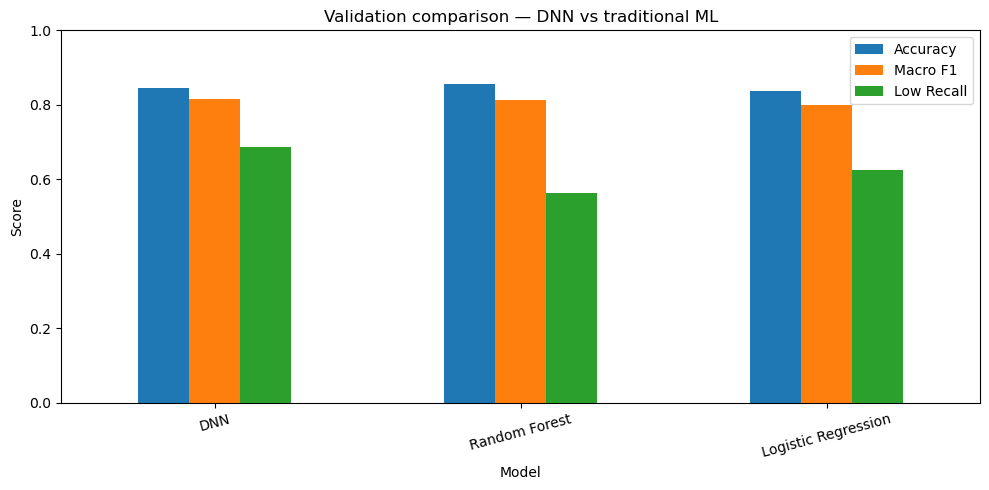

In [7]:
plot_data = comparison.set_index("Model")[["Accuracy", "Macro F1", "Low Recall"]]
ax = plot_data.plot(kind="bar", figsize=(10, 5))
ax.set(title="Validation comparison — DNN vs traditional ML",
       xlabel="Model", ylabel="Score", ylim=(0, 1))
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 8. Classification reports and confusion matrices

Confusion matrices show which performance categories each model confuses. These results are from the **validation set**, not the final test set.


 ================== Logistic Regression ==================
              precision    recall  f1-score   support

         Low       0.67      0.62      0.65        16
     Average       0.84      0.86      0.85        57
        Good       0.90      0.90      0.90        31

    accuracy                           0.84       104
   macro avg       0.80      0.80      0.80       104
weighted avg       0.83      0.84      0.84       104


 ================== Random Forest ==================
              precision    recall  f1-score   support

         Low       0.82      0.56      0.67        16
     Average       0.81      0.96      0.88        57
        Good       1.00      0.81      0.89        31

    accuracy                           0.86       104
   macro avg       0.88      0.78      0.81       104
weighted avg       0.87      0.86      0.85       104


 ================== DNN ==================
              precision    recall  f1-score   support

         Low       0.69  

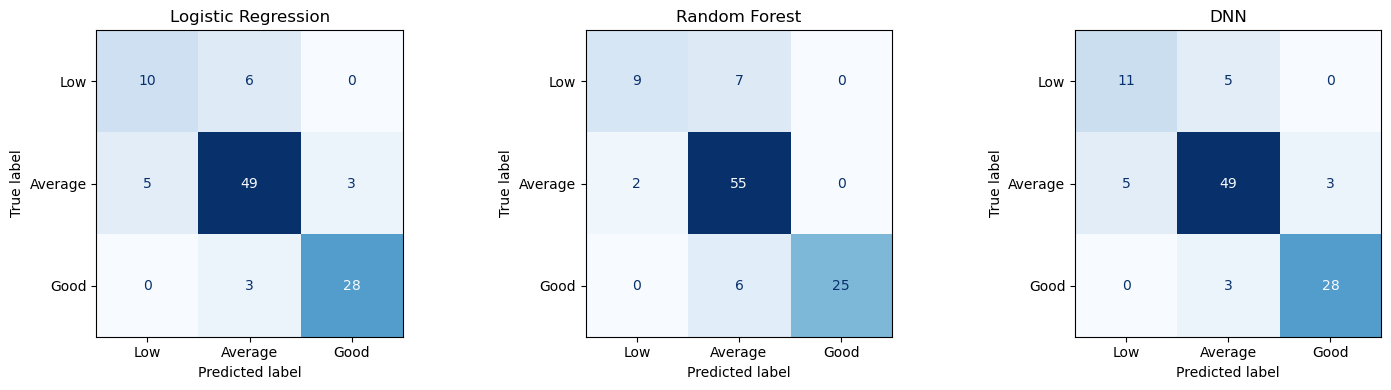

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    print("\n", "=" * 18, name, "=" * 18)
    print(classification_report(y_val, pred, labels=LABELS, zero_division=0))
    matrix = confusion_matrix(y_val, pred, labels=LABELS)
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 9. Save traditional ML models and comparison results

The DNN is already saved from Notebook 03. We save both ML pipelines, which include their own fitted preprocessing.

**Important:** We do not deploy the 'winner' automatically based on validation performance. The project requires a DNN-based application; Notebook 05 will document the DNN's final evaluation alongside the ML baselines.

Files saved to `models/`:
- `logistic_regression_pipeline.joblib`
- `random_forest_pipeline.joblib`
- `model_comparison_validation.csv`
- `model_comparison_metadata.json`


In [9]:
joblib.dump(ml_models["Logistic Regression"], OUTPUT_DIR / "logistic_regression_pipeline.joblib")
joblib.dump(ml_models["Random Forest"], OUTPUT_DIR / "random_forest_pipeline.joblib")
comparison.to_csv(OUTPUT_DIR / "model_comparison_validation.csv", index=False)

metadata = {
    "stage": "validation_model_comparison",
    "dataset": "student-por.csv",
    "prediction_stage": "after_G2",
    "seed": SEED,
    "selected_features": features,
    "models": list(predictions.keys()),
    "ranking_metric": "validation_macro_f1",
    "best_validation_macro_f1_model": str(comparison.iloc[0]["Model"]),
    "test_set_evaluated": False,
}
(OUTPUT_DIR / "model_comparison_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

# Confirm saved ML pipelines produce the same validation predictions.
for name, filename in [
    ("Logistic Regression", "logistic_regression_pipeline.joblib"),
    ("Random Forest", "random_forest_pipeline.joblib")
]:
    loaded = joblib.load(OUTPUT_DIR / filename)
    np.testing.assert_array_equal(loaded.predict(X_val), predictions[name])
print("PASS — Both ML pipelines reloaded and predictions match.")
print("Saved validation comparison. Test set remains reserved.")

PASS — Both ML pipelines reloaded and predictions match.
Saved validation comparison. Test set remains reserved.


## 10. Viva-ready summary and next step

> We compared our DNN with Logistic Regression and Random Forest using the same 12 selected features and the same training/validation split. Logistic Regression is a simple linear baseline, while Random Forest captures nonlinear feature interactions. We used training-only preprocessing and measured accuracy, macro precision, macro recall, macro F1 and Low-category recall. We also examined confusion matrices. These are validation results; we reserved the test set for a final, one-time evaluation.

### Next: Notebook 05 — Final Model Evaluation
Load all three saved models and evaluate **once** on the reserved 130-student test set. Then save the final DNN artifacts for Streamlit. Do not tune models after seeing the test results.
